# EW-RIE*: Làm sạch ma trận tương quan có trọng số mũ bằng lý thuyết ma trận ngẫu nhiên
### Ứng dụng: danh mục phương sai nhỏ nhất trên HOSE

**Câu hỏi nghiên cứu.** Ở thị trường mới nổi (N cổ phiếu lớn so với số phiên T, biến động thay đổi theo chế độ, cấm bán khống), bộ ước lượng ma trận hiệp phương sai nào cho danh mục rủi ro thấp nhất ngoài mẫu?

**Phương pháp đề xuất: EW-RIE\***
1. Ước lượng tương quan có trọng số mũ (half-life *h*) để phản ứng nhanh với thay đổi chế độ:
   $E = \sum_t w_t x_t x_t^\top = C^{1/2} W C^{1/2}$, với $W = \sum_t w_t y_t y_t^\top$ là nhiễu.
2. R-transform của nhiễu (tổng tự do các ma trận hạng 1): $R_W(g) = \sum_t \dfrac{w_t}{1 - N w_t g}$.
3. Phép thế nhân (BBP 2016) cho trị riêng làm sạch:
   $\xi_i = \lambda_i\,\dfrac{\operatorname{Im}\gamma(z_i)}{\operatorname{Im} t_E(z_i)}$, $z_i = \lambda_i - i\eta$, $t_E = z g_E(z) - 1$, với $\gamma$ là nghiệm của $\gamma\,R_W(\gamma) = t_E$.
   Trọng số đều ⇒ trùng công thức RIE cổ điển $\lambda/|1-q+qzg|^2$.
4. Ba chi tiết kỹ thuật (đóng góp của nhóm):
   - **Chọn đúng nhánh nghiệm** bằng tiếp tục giải tích: đi từ $t\approx 0$ (nơi $\gamma\approx t$) theo tia đến $t_E$.
   - **Ngoại lai** (trị riêng cô lập, ví dụ mode thị trường): đánh giá trên trục thực với $g$ bỏ-một, $\xi = \lambda\,\gamma'(t)$. Công thức BBP gốc với $\eta = N^{-1/2}$ ước lượng sai mode thị trường.
   - **Hiệu chỉnh N hữu hạn**: so với cùng công thức trên phổ nhiễu thuần (khớp thang theo trung vị).

**Đối chứng:** ma trận mẫu, Ledoit–Wolf (2004), NL-LW (Ledoit–Wolf 2020), MP-clip (Laloux 1999), RIE (Bun–Bouchaud–Potters 2016/17), bản EW với $q_{\text{eff}}$, EW-NL-LW, và biến thể VS (chuẩn hóa biến động EWMA).

**Kết quả hiện có (HOSE 2009–3/2020, N=100, T=250, h=60):**

| | Bán khống | Chỉ mua |
|---|---|---|
| NL-LW | 15,14% | 15,95% |
| EW-NL-LW | 14,43% | 15,28% |
| EW-RIE ($q_{\text{eff}}$) | 15,97% | 16,41% |
| **EW-RIE\*** | **14,24%** | **15,21%** |

EW-RIE\* tốt hơn có ý nghĩa (bootstrap khối, 95%) so với mọi đối chứng, ở mọi half-life 30/60/120. Trên dữ liệu tổng hợp, EW-RIE\* chỉ cách oracle ≈1%.
Hạn chế: dữ liệu đến 3/2020; survivorship bias; VS **không** được xác nhận trong mô phỏng GARCH.

**Tài liệu chính:** Bun, Bouchaud & Potters (2016) *IEEE Trans. Inf. Theory* 62(12); (2017) *Physics Reports* 666; Ledoit & Wolf (2020) *Ann. Statist.*; Laloux et al. (1999) *PRL*; Jagannathan & Ma (2003) *J. Finance*.

## Phân công nhóm

| Mã | Việc | Đầu ra | Mục trong notebook |
|---|---|---|---|
| **T1** | Dữ liệu 2020–2025 (vnstock/nguồn trả phí) + **mã đã hủy niêm yết** để loại survivorship bias | `prices.csv`, `values.csv` | §2, ô T1 |
| **T2** | Độ vững: chi phí GD thực tế (phí + thuế 0,1%), tần suất tái cân bằng 5/21/63 phiên, xử lý phiên không giao dịch (~18%) | Bảng độ vững | §6, ô T2 |
| **T3** | Đối chứng & kiểm định chuẩn: danh mục 1/N, mô hình nhân tố, DCC-GARCH; kiểm định chênh lệch phương sai Ledoit–Wolf (2011, HAC), Sharpe (Jobson–Korkie/Memmel) | Bảng kiểm định | §6, ô T3 |
| **T4** | Lý thuyết: chứng minh tính đúng của việc chọn nhánh, điều kiện ngoại lai, hiệu chỉnh N hữu hạn; **rà soát tính mới** (đọc toàn văn BBP 2016 §III và Phys. Rep. 2017) | Mục Methodology (LaTeX) | — |
| **T5** | Vì sao VS giúp trên HOSE nhưng không trong GARCH? (biến động riêng lẻ, tương quan đổi theo chế độ…) | Ghi chú + thí nghiệm | §6, ô T5 |
| **T6** | Mở rộng: N = 50/150, cửa sổ T, VN30/HNX | Bảng phụ lục | §5 (đổi CONFIG) |
| **T7** | Viết bài, nhắm tạp chí (kiểm tra hạng Q trên Scimago) | Bản thảo | — |

**Quy ước:** mỗi người làm trên bản sao notebook (`File → Save a copy in Drive`), ghi kết quả vào thư mục chung. Đổi tham số ở ô CONFIG, không sửa thư viện ở §1 trừ khi đã thống nhất.

**Bản này chỉ làm T1** (dữ liệu, lịch sử niêm yết, mã hủy niêm yết, mã đứng giá). Các ô của thầy giữ nguyên; ô thêm có dấu **▶**. T2, T3, T5, T6 làm sau khi T1 xong.

## 0. Cài đặt & cấu hình

In [1]:
import os, sys, subprocess, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.covariance import LedoitWolf
warnings.filterwarnings("ignore")

IN_COLAB = "google.colab" in sys.modules
print("Colab:", IN_COLAB, "| numpy", np.__version__, "| pandas", pd.__version__)

Colab: False | numpy 2.5.3 | pandas 3.0.5


In [2]:
# ======================= CONFIG =======================
CONFIG = dict(
    N=100,            # số mã thanh khoản nhất mỗi kỳ
    WINDOW=250,       # cửa sổ ước lượng (phiên)
    REB=21,           # tái cân bằng mỗi REB phiên
    COST=0.0025,      # chi phí 1 chiều (giả định, T2 cần chỉnh)
    HL_EW=60,         # half-life trọng số mũ
    HL_VOL=20,        # half-life chuẩn hóa biến động (VS)
    MAX_ABS_RET=0.15, # |r| > ngưỡng coi là lỗi dữ liệu (biên độ HOSE ±7%)
    ZERO_MAX=0.20,    # ▶ loại mã đứng giá: tỷ lệ phiên r = 0 trong cửa sổ quá khứ > ZERO_MAX (1.0 = không lọc)
    QUICK=False,      # True: chạy nhanh với ít bộ ước lượng
)
DATA_SOURCE = "csv"      # ▶ "csv": dữ liệu HOSE 2015–11/2026 (có mã hủy niêm yết) | "github" (2006–3/2020, cũ) | "vnstock"
DATA_URL = "https://raw.githubusercontent.com/chinguyenkhac/data_HOSE/main/data_hose"   # ▶ link dữ liệu T1 trên GitHub
WORKDIR = os.environ.get("RMT_WORKDIR", "/content/rmt" if IN_COLAB else "./rmt_work")
DATA_DIR = f"{WORKDIR}/data_hose"      # ▶ nơi lưu dữ liệu đã tải
os.makedirs(WORKDIR, exist_ok=True)
CONFIG

{'N': 100,
 'WINDOW': 250,
 'REB': 21,
 'COST': 0.0025,
 'HL_EW': 60,
 'HL_VOL': 20,
 'MAX_ABS_RET': 0.15,
 'ZERO_MAX': 0.2,
 'QUICK': False}

### ▶ Giao diện hình dùng chung
Một bảng màu và kiểu hình thống nhất cho các hình bên dưới.

In [3]:
# ▶ Giao diện hình dùng chung: một bảng màu cố định cho mỗi phương pháp, nền sáng, lưới nhạt, bỏ khung trên/phải
from matplotlib.colors import TwoSlopeNorm
COL = {"NL-LW": "#2a78d6", "EW-NL-LW": "#eb6834", "EW-RIE*": "#1baf7a", "EW-WeSpeR": "#8e44ad",
       "VS-NL-LW": "#eda100", "VS-RIE": "#b8860b", "1/N": "#9aa0a6", "PCA-auto": "#5d6d7e", "DCC-GARCH(1,1)": "#34495e"}
GREY = "#b8bcc2"
color_of = lambda name: COL.get(name, GREY)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": "white",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "grid.color": "#e6e8eb", "grid.linewidth": .8,
    "legend.frameon": False, "legend.fontsize": 9})

## 1. Thư viện: các bộ ước lượng
Không cần sửa. Mỗi bộ ước lượng nhận ma trận lợi suất `X` (T×N) và trả về ma trận hiệp phương sai N×N.

In [4]:
# ---------- tiện ích ----------
def cov_to_corr(S):
    sd = np.sqrt(np.diag(S)); return S / np.outer(sd, sd), sd

def renorm(C):
    d = np.sqrt(np.diag(C)); return C / np.outer(d, d)

# ---------- đối chứng cổ điển ----------
def est_sample(X): return np.cov(X, rowvar=False)

def est_lw(X): return LedoitWolf().fit(X).covariance_

def nl_lw_S(S, n):
    # Ledoit & Wolf (2020), co phi tuyến giải tích; S: hiệp phương sai, n: cỡ mẫu (hiệu dụng)
    p = len(S); lam, U = np.linalg.eigh(S); lam = np.maximum(lam, 1e-12)
    L = np.tile(lam, (p, 1)).T; H = n ** (-1 / 3) * L.T; x = (L - L.T) / H
    ft = (3 / 4 / np.sqrt(5)) * np.mean(np.maximum(1 - x**2 / 5, 0) / H, axis=1)
    with np.errstate(divide="ignore", invalid="ignore"):
        Hf = (-3/10/np.pi) * x + (3/4/np.sqrt(5)/np.pi) * (1 - x**2/5) * np.log(np.abs((np.sqrt(5) - x) / (np.sqrt(5) + x)))
    e = np.isclose(np.abs(x), np.sqrt(5)); Hf[e] = (-3/10/np.pi) * x[e]
    Ht = np.mean(Hf / H, axis=1); c = p / n
    d = lam / ((np.pi*c*lam*ft)**2 + (1 - c - np.pi*c*lam*Ht)**2)
    return (U * d) @ U.T

def est_nllw(X):
    Xc = X - X.mean(0); n = len(X) - 1
    return nl_lw_S(Xc.T @ Xc / n, n)

def mp_corr(C, q):
    lam, V = np.linalg.eigh(C); N = len(C)
    lp = (1 - lam[-1] / N) * (1 + np.sqrt(q))**2
    noise = lam < lp; lam = lam.copy()
    if noise.any(): lam[noise] = lam[noise].mean()
    return renorm((V * lam) @ V.T)

def rie_corr(C, q):
    # RIE Bun–Bouchaud–Potters (2016) + hiệu chỉnh N hữu hạn (2017, §8). Đây là bản GỐC (đối chứng).
    N = len(C); lam, V = np.linalg.eigh(C); lam = np.maximum(lam, 1e-10)
    z = lam - 1j / np.sqrt(N); g = (1 / (z[:, None] - lam[None, :])).mean(1)
    xi = lam / np.abs(1 - q + q*z*g)**2
    s2 = lam[0] / (1 - np.sqrt(q))**2 if q < 1 else lam.mean()
    lp, lm = s2 * (1 + np.sqrt(q))**2, s2 * (1 - np.sqrt(q))**2
    gmp = (z + s2*(q - 1) - np.sqrt(z - lm) * np.sqrt(z - lp)) / (2*q*z*s2)
    xi = xi * np.maximum(1, s2 * np.abs(1 - q + q*z*gmp)**2 / lam)
    xi *= N / xi.sum(); return renorm((V * xi) @ V.T)

def _corr_wrap(cleaner):
    def est(X):
        T, N = X.shape; C, sd = cov_to_corr(np.cov(X, rowvar=False))
        return cleaner(C, N / T) * np.outer(sd, sd)
    return est
est_mp, est_rie = _corr_wrap(mp_corr), _corr_wrap(rie_corr)

In [5]:
# ---------- EW (trọng số mũ) và VS (chuẩn hóa biến động) ----------
def ew_weights(T, hl):
    w = 0.5 ** ((T - 1 - np.arange(T)) / hl); return w / w.sum()

def ew_corr(X, w):
    Xc = X - w @ X; S = (Xc * w[:, None]).T @ Xc
    sd = np.sqrt(np.diag(S)); return S / np.outer(sd, sd), sd

def make_ew(cleaner, hl):
    # cleaner(C, w) -> tương quan đã làm sạch
    def est(X):
        w = ew_weights(len(X), hl); C, sd = ew_corr(X, w)
        return cleaner(C, w) * np.outer(sd, sd)
    return est

def ewma_standardize(X, hl):
    lam = 0.5 ** (1 / hl); s2 = X[:hl].var(0) + 1e-10; Z = np.empty_like(X)
    for t in range(len(X)):
        Z[t] = X[t] / np.sqrt(s2); s2 = lam * s2 + (1 - lam) * X[t]**2
    return Z, np.sqrt(s2)

def make_vs(corr_cleaner, hl_vol):
    # corr_cleaner(Z) -> ma trận tương quan đã làm sạch của lợi suất chuẩn hóa Z
    def est(X):
        Z, sig = ewma_standardize(X, hl_vol); Z = Z[hl_vol:]
        return corr_cleaner(Z) * np.outer(sig, sig)
    return est

In [6]:
# ---------- EW-RIE*: RIE chính xác cho trọng số mũ (phương pháp đề xuất) ----------
_STATS = {"fail": 0, "total": 0}; _NULL_CACHE = {}

def _F(g, t, a, w):
    d = 1 - a[None, :] * g[:, None]; R = (w[None, :] / d).sum(1)
    return g * R - t, R, (w[None, :] * a[None, :] / d**2).sum(1)

def _solve_gamma(t, a, w, g0, iters=30):
    # Newton có tìm kiếm lùi cho  γ·R_W(γ) = t  (vector phức), a = N·w
    g = g0.copy(); f, R, dR = _F(g, t, a, w)
    for _ in range(iters):
        step = f / (R + g * dR); lam_ = np.ones(len(g))
        for _ in range(30):
            gn = g - lam_ * step; fn, Rn, dRn = _F(gn, t, a, w)
            bad = ~(np.abs(fn) < np.abs(f)) & (np.abs(f) > 1e-14)
            if not bad.any(): break
            lam_[bad] *= 0.5
        keep = bad | ~np.isfinite(fn)
        gn[keep], fn[keep], Rn[keep], dRn[keep] = g[keep], f[keep], R[keep], dR[keep]
        g, f, R, dR = gn, fn, Rn, dRn
        if np.max(np.abs(f)) < 1e-13: break
    return g, np.abs(f)

def _continuation(t, a, w, steps=60, strict=True):
    # Nhánh chính: γ ≈ t khi t→0, đi theo tia s·t (s: 0→1)
    g = 1e-3 * t
    for s in np.geomspace(1e-3, 1.0, steps):
        g, res = _solve_gamma(s * t, a, w, g)
    ok = np.isfinite(g) & (res < 1e-8)
    if strict and not ok.all(): raise RuntimeError("Newton không hội tụ")
    return g if strict else (g, ok)

def _xi(spec, x, w, N, eta):
    z = x - 1j * eta; g = (1 / (z[:, None] - spec[None, :])).mean(1); t = z * g - 1
    gam, ok = _continuation(t, N * w, w, strict=False)
    gam[~ok] = (t / (1 + N * (w**2).sum() * t))[~ok]       # dự phòng (thực tế: 0 lần trên HOSE)
    _STATS["fail"] += int((~ok).sum()); _STATS["total"] += len(ok)
    return x * gam.imag / t.imag

def _xi_outliers(lam, idx, w, N):
    a = N * w; out = np.empty(len(idx))
    for k, i in enumerate(idx):
        g = np.sum(1 / (lam[i] - np.delete(lam, i))) / N     # Stieltjes bỏ-một trên trục thực
        t = np.array([lam[i] * g - 1 + 0j])
        try:
            gam = _continuation(t, a, w); _, R, dR = _F(gam, t, a, w)
            out[k] = lam[i] * np.real(1 / (R + gam * dR))[0]   # ξ = λ·γ'(t)
        except RuntimeError:
            out[k] = _xi(lam, lam[i:i+1], w, N, 1 / np.sqrt(N))[0]
    return out

def _null_spectrum(N, w, reps=8, seed=0):
    key = (N, len(w), round(float(w[-1]), 12))
    if key not in _NULL_CACHE:
        rng = np.random.default_rng(seed)
        ev = [np.linalg.eigvalsh((Y * w[:, None]).T @ Y) for Y in (rng.standard_normal((len(w), N)) for _ in range(reps))]
        _NULL_CACHE[key] = np.sort(np.concatenate(ev))
    return _NULL_CACHE[key]

def ew_rie_corr(C, w, debias=True):
    N = len(C); lam, V = np.linalg.eigh(C); lam = np.maximum(lam, 1e-10); eta = 1 / np.sqrt(N)
    null = _null_spectrum(N, w); s2 = np.median(lam) / np.median(null)
    D = lam[:, None] - lam[None, :]
    dens = (eta / (D**2 + eta**2)).sum(1) - 1 / eta            # mật độ lân cận (bỏ tự thân)
    out = np.where(dens < 0.1 / eta)[0]; bulk = np.setdiff1d(np.arange(N), out)
    xi = np.empty(N)
    xi[bulk] = _xi(lam, lam[bulk], w, N, eta)
    if len(out): xi[out] = _xi_outliers(lam, out, w, N)
    if debias and len(bulk):
        xi_null = _xi(null, lam[bulk] / s2, w, N, eta)
        xi[bulk] *= np.maximum(1, 1 / np.maximum(xi_null, 1e-6))
    xi = np.maximum(xi, 1e-8); xi *= N / xi.sum()
    return renorm((V * xi) @ V.T)

In [7]:
# ---------- Danh sách bộ ước lượng ----------
def build_estimators(cfg):
    hl, hv = cfg["HL_EW"], cfg["HL_VOL"]
    E = {
        "Sample": est_sample,
        "Ledoit-Wolf": est_lw,
        "NL-LW": est_nllw,
        "MP-clip": est_mp,
        "RIE": est_rie,
        "VS-NL-LW": make_vs(lambda Z: renorm(nl_lw_S(np.cov(Z, rowvar=False), len(Z) - 1)), hv),
        "VS-RIE": make_vs(lambda Z: rie_corr(np.corrcoef(Z, rowvar=False), Z.shape[1] / len(Z)), hv),
        "EW-NL-LW": make_ew(lambda C, w: renorm(nl_lw_S(C, 1 / (w**2).sum())), hl),
        "EW-RIE (q_eff)": make_ew(lambda C, w: rie_corr(C, len(C) * (w**2).sum()), hl),
        "EW-RIE*": make_ew(ew_rie_corr, hl),
    }
    if cfg["QUICK"]:
        E = {k: E[k] for k in ["Sample", "NL-LW", "RIE", "EW-NL-LW", "EW-RIE*"]}
    return E

## 1b. Kiểm thử (chạy trước mọi thay đổi)
1) Trọng số đều ⇒ EW-RIE\* trùng RIE cổ điển. 2) So với oracle trên dữ liệu tổng hợp đã biết C thật.

In [8]:
rng = np.random.default_rng(0); N_, T_ = 100, 250
X = rng.standard_normal((T_, N_)); Cs = np.corrcoef(X, rowvar=False); lam = np.linalg.eigvalsh(Cs)
z = lam - 0.1j; g = (1 / (z[:, None] - lam[None, :])).mean(1); q = N_ / T_
err = np.max(np.abs(_xi(lam, lam, np.full(T_, 1 / T_), N_, 0.1) - lam / np.abs(1 - q + q*z*g)**2) / lam)
print(f"[Test 1] trọng số đều: sai lệch tương đối max = {err:.1e}"); assert err < 1e-10

[Test 1] trọng số đều: sai lệch tương đối max = 2.9e-15


In [9]:
def gmv(S):
    w = np.linalg.solve(S, np.ones(len(S))); return w / w.sum()

def factor_corr(N, rng):
    sec = rng.integers(0, 8, N); B = np.zeros((N, 9))
    B[:, 0] = rng.uniform(.4, .8, N); B[np.arange(N), 1 + sec] = rng.uniform(.2, .5, N)
    return renorm(B @ B.T + np.diag(rng.uniform(.3, .6, N)))

rows = []
for hl in (30, 60):
    w = ew_weights(T_, hl); acc = {}
    for rep in range(6):
        Ct = factor_corr(N_, rng); X = rng.standard_normal((T_, N_)) @ np.linalg.cholesky(Ct).T
        C, _ = ew_corr(X, w); lam, V = np.linalg.eigh(C)
        Co = renorm((V * np.einsum("ij,jk,ki->i", V.T, Ct, V)) @ V.T)    # oracle RIE
        wo = gmv(Ct); best = wo @ Ct @ wo
        for k, Ch in {"EW-Sample": C, "EW-RIE (q_eff)": rie_corr(C, N_ * (w**2).sum()),
                      "EW-NL-LW": renorm(nl_lw_S(C, 1 / (w**2).sum())), "EW-RIE*": ew_rie_corr(C, w),
                      "Oracle": Co}.items():
            wh = gmv(Ch); acc.setdefault(k, []).append(wh @ Ct @ wh / best)
    rows += [dict(hl=hl, method=k, risk_ratio=np.mean(v)) for k, v in acc.items()]
t2 = pd.DataFrame(rows).pivot(index="method", columns="hl", values="risk_ratio").round(3)
print("[Test 2] rủi ro GMV / rủi ro tối ưu (1 = hoàn hảo), mô hình nhân tố:"); display(t2)
assert (t2.loc["EW-RIE*"] < t2.loc["EW-RIE (q_eff)"]).all()

[Test 2] rủi ro GMV / rủi ro tối ưu (1 = hoàn hảo), mô hình nhân tố:


hl,30,60
method,,
EW-NL-LW,1.822,1.269
EW-RIE (q_eff),1.782,1.629
EW-RIE*,1.290,1.210
EW-Sample,2.929,2.048
Oracle,1.278,1.201


## 2. Dữ liệu
Ba lựa chọn qua `DATA_SOURCE`. Kết quả chuẩn: `P` (giá đóng cửa điều chỉnh, dòng = ngày, cột = mã) và `V` (giá trị giao dịch, cùng kích thước).

### ▶ T1.0 — lấy dữ liệu từ GitHub
Bộ `data_hose/` (vnstock 5.2.2, nguồn VCI; lịch sử niêm yết từ HSX + Vietstock + VCI) nằm trong repo public `chinguyenkhac/data_HOSE`. Ô này tải 5 file về `DATA_DIR`; ô nạp của thầy (ngay dưới) đọc `prices.csv`, `values.csv` từ đó.

In [10]:
import urllib.request
HOSE_FILES = ["prices.csv", "values.csv", "volumes.csv", "security_master.csv", "missing_tickers.csv"]
os.makedirs(DATA_DIR, exist_ok=True)
for f in HOSE_FILES:
    if not os.path.exists(f"{DATA_DIR}/{f}"):
        urllib.request.urlretrieve(f"{DATA_URL}/{f}", f"{DATA_DIR}/{f}")
print("Nguồn:", DATA_URL)
print("Đã có trong", DATA_DIR, ":", ", ".join(f"{f} ({os.path.getsize(f'{DATA_DIR}/{f}') / 1e6:.1f} MB)" for f in HOSE_FILES))

Nguồn: https://raw.githubusercontent.com/chinguyenkhac/data_HOSE/main/data_hose
Đã có trong ./rmt_work/data_hose : prices.csv (6.2 MB), values.csv (12.1 MB), volumes.csv (7.6 MB), security_master.csv (0.1 MB), missing_tickers.csv (0.0 MB)


In [11]:
def sh(cmd, cwd=None):
    r = subprocess.run(cmd, shell=True, cwd=cwd, capture_output=True, text=True)
    if r.returncode: print(r.stderr[-500:])
    return r.returncode

def load_github(workdir):
    # Giá ngày 2006–03/2020 (github.com/88d52bdba0366127fffca9dfa93895/vnstock-data);
    # danh sách mã HOSE (github.com/vuthanhdatt/web-indicator, năm 2022 → có survivorship bias)
    px_repo, ls_repo = f"{workdir}/vnstock-data", f"{workdir}/web-indicator"
    if not os.path.isdir(f"{px_repo}/tickers"):
        sh(f"git clone -q --depth 1 --filter=blob:none --sparse https://github.com/88d52bdba0366127fffca9dfa93895/vnstock-data {px_repo}")
        sh("git sparse-checkout set tickers", cwd=px_repo)
    if not os.path.isdir(f"{ls_repo}/datas/hose"):
        sh(f"git clone -q --depth 1 --filter=blob:none --sparse https://github.com/vuthanhdatt/web-indicator {ls_repo}")
        sh("git sparse-checkout set datas/hose", cwd=ls_repo)
    hose = {f[:-4].lower() for f in os.listdir(f"{ls_repo}/datas/hose")}
    px, val = {}, {}
    for f in sorted(os.listdir(f"{px_repo}/tickers")):
        t = f[:-4]
        if t not in hose: continue
        d = pd.read_csv(f"{px_repo}/tickers/{f}", parse_dates=["date"]).drop_duplicates("date").set_index("date")
        d = d[d["close"] > 0]; px[t.upper()] = d["close"]; val[t.upper()] = d["close"] * d["volume"]
    return pd.DataFrame(px).sort_index(), pd.DataFrame(val)

def load_csv(price_path, value_path=None):
    P = pd.read_csv(price_path, index_col=0, parse_dates=True).sort_index()
    V = pd.read_csv(value_path, index_col=0, parse_dates=True).reindex(P.index) if value_path else P * 0 + 1
    return P, V

def load_vnstock(symbols, start="2006-01-01", end="2025-12-31"):
    # T1: API vnstock thay đổi theo phiên bản – KIỂM TRA lại trước khi dùng (pip install -U vnstock).
    from vnstock import Vnstock
    px, val = {}, {}
    for s in symbols:
        try:
            d = Vnstock().stock(symbol=s, source="VCI").quote.history(start=start, end=end, interval="1D")
            d = d.set_index(pd.to_datetime(d["time"]))
            px[s] = d["close"]; val[s] = d["close"] * d["volume"]   # LƯU Ý: kiểm tra giá đã điều chỉnh chưa
        except Exception as e:
            print(s, "lỗi:", e)
        time.sleep(0.3)
    return pd.DataFrame(px).sort_index(), pd.DataFrame(val).sort_index()

if DATA_SOURCE == "github":
    P, V = load_github(WORKDIR)
elif DATA_SOURCE == "csv":
    P, V = load_csv(f"{DATA_DIR}/prices.csv", f"{DATA_DIR}/values.csv")   # ▶ T1: dữ liệu tải từ GitHub
else:
    P, V = load_vnstock(["VNM", "FPT", "VCB"])         # T1: thay bằng danh sách đầy đủ, gồm mã đã hủy niêm yết

P = P[P.notna().sum(1) >= 20]; V = V.reindex(P.index)
print(f"{P.shape[1]} mã, {P.shape[0]} phiên: {P.index[0].date()} → {P.index[-1].date()}")

493 mã, 2957 phiên: 2015-01-05 → 2026-11-10


### ▶ T1.1 — chỉ giữ giá trong khoảng niêm yết HOSE
`security_master.csv`: mỗi dòng = một giai đoạn niêm yết (ngày niêm yết/hủy, lý do). Giá nằm ngoài khoảng này bị loại; **mã hủy niêm yết được giữ** trong thời gian còn niêm yết.

In [12]:
# Đọc thêm khối lượng, lịch sử niêm yết (security_master) và danh sách mã thiếu giá
P_RAW = P.copy()                                                         # P, V do ô nạp của thầy ở trên
Q = pd.read_csv(f"{DATA_DIR}/volumes.csv", index_col=0, parse_dates=True).reindex(index=P_RAW.index, columns=P_RAW.columns)
MASTER_RAW = pd.read_csv(f"{DATA_DIR}/security_master.csv", parse_dates=["listing_date", "delisting_date"])
MISSING = pd.read_csv(f"{DATA_DIR}/missing_tickers.csv")
MASTER = MASTER_RAW.drop_duplicates(subset=["ticker", "listing_date", "delisting_date"]).reset_index(drop=True)

# Mặt nạ "đang niêm yết": True nếu ngày nằm trong [ngày niêm yết, ngày hủy] của một giai đoạn niêm yết (một mã có thể có nhiều giai đoạn)
INWIN = pd.DataFrame(False, index=P_RAW.index, columns=P_RAW.columns)
for r in MASTER.itertuples():
    if r.ticker in INWIN:
        end_ok = (INWIN.index <= r.delisting_date) if pd.notna(r.delisting_date) else True
        INWIN.loc[(INWIN.index >= r.listing_date) & end_ok, r.ticker] = True

OUTSIDE = P_RAW.notna() & ~INWIN                                         # quan sát giá nằm ngoài khoảng niêm yết
P = P_RAW.where(INWIN)
V = V.reindex(index=P_RAW.index, columns=P_RAW.columns).where(INWIN)
Q = Q.where(INWIN)
P = P[P.notna().sum(1) >= 20]; V = V.reindex(P.index); Q = Q.reindex(P.index)

# Mã đã rời HOSE (không còn niêm yết ở giai đoạn nào)
DELISTED = set(MASTER.loc[MASTER.delisting_date.notna(), "ticker"]) - set(MASTER.loc[MASTER.delisting_date.isna(), "ticker"])
print(f"{P.shape[1]} mã có giá, {P.shape[0]} phiên: {P.index[0].date()} → {P.index[-1].date()} | "
      f"thiếu giá: {len(MISSING)} mã | quan sát ngoài khoảng niêm yết (đã loại): {int(OUTSIDE.sum().sum())}")

493 mã có giá, 2957 phiên: 2015-01-05 → 2026-11-10 | thiếu giá: 19 mã | quan sát ngoài khoảng niêm yết (đã loại): 101


Tỷ lệ |r| > ngưỡng: 0.0005%
Tỷ lệ phiên giá không đổi (r = 0): 15.3%


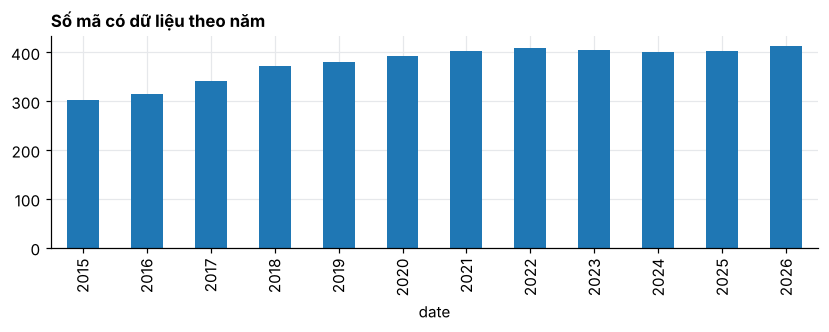

In [13]:
# Kiểm tra chất lượng dữ liệu
R_all = np.log(P).diff()
print("Tỷ lệ |r| > ngưỡng:", f"{(R_all.abs() > CONFIG['MAX_ABS_RET']).sum().sum() / R_all.notna().sum().sum():.4%}")
print("Tỷ lệ phiên giá không đổi (r = 0):", f"{(R_all == 0).sum().sum() / R_all.notna().sum().sum():.1%}")
P.notna().groupby(P.index.year).any().sum(axis=1).plot.bar(figsize=(9, 2.5), title="Số mã có dữ liệu theo năm"); plt.show()

### ▶ T1 – Dữ liệu, lịch sử niêm yết và mã hủy niêm yết
- **T1a** tổng quan · **T1b** số cổ phiếu niêm yết / hủy niêm yết theo năm và lý do · **T1c** màng sàng lọc: mã hủy đi qua từng lớp thế nào · **T1d** mã ngừng giao dịch giữa kỳ giữ · **T1e** mã đứng giá.

**Màng sàng lọc hiện tại** (§3 của thầy + một dòng `ZERO_MAX`):
0. Chỉ giữ giá trong khoảng niêm yết (T1.1).
1. Mỗi kỳ tái cân bằng (21 phiên): mã phải có ≥ 95% phiên có giá trong 250 phiên trước **và** có giá ngày hôm trước.
2. Mã có > `ZERO_MAX` = 20% phiên đứng giá (r = 0) trong cửa sổ bị loại.
3. Giữ N = 100 mã có giá trị giao dịch trung vị cao nhất. Trong kỳ giữ, mã ngừng giao dịch nhận lợi suất 0.

**Cột "lý do hủy" không được dùng trong bộ lọc**: mọi loại hủy được xử lý như nhau; lý do chỉ dùng để báo cáo.

In [14]:
# T1a. Tổng quan dữ liệu sau khi lọc theo khoảng niêm yết
R_q = np.log(P).diff(); n_ret = int(R_q.notna().sum().sum()); in_win = INWIN.reindex(P.index)
# mỗi giai đoạn niêm yết chỉ tính 1 lượt hủy (APC có 2 dòng hủy trùng ngày niêm yết trong security_master → giữ ngày hủy sau)
dl = (MASTER.dropna(subset=["delisting_date"]).sort_values("delisting_date").drop_duplicates(["ticker", "listing_date"], keep="last"))
has_px = dl.ticker.isin(P.columns)

TQ = pd.Series({
    "Khoảng thời gian": f"{P.index[0].date()} → {P.index[-1].date()} ({len(P)} phiên)",
    "Số mã trong security_master / có giá / thiếu giá": f"{MASTER.ticker.nunique()} / {P.shape[1]} / {len(MISSING)}",
    "Lượt hủy niêm yết (có giá / thiếu giá)": f"{len(dl)} ({int(has_px.sum())} / {int((~has_px).sum())})",
    "Quan sát ngoài khoảng niêm yết (đã loại)": f"{int(OUTSIDE.sum().sum())} (mã: {', '.join(OUTSIDE.sum()[OUTSIDE.sum() > 0].index)})",
    "% ô có giá trong khoảng niêm yết": f"{100 * (P.notna() & in_win).sum().sum() / in_win.sum().sum():.1f}%",
    "% phiên đứng giá (r = 0)": f"{100 * (R_q == 0).sum().sum() / n_ret:.1f}%",
    "Phiên |r| > 15% (đặt = 0) / khối lượng = 0 mà có giá / giá ≤ 0":
        f"{int((R_q.abs() > CONFIG['MAX_ABS_RET']).sum().sum())} / {int(((Q == 0) & P.notna()).sum().sum())} / {int((P <= 0).sum().sum())}"})
display(TQ.to_frame("giá trị"))

,giá trị
Khoảng thời gian,2015-01-05 → 2026-11-10 (2957 phiên)
Số mã trong security_master / có giá / thiếu giá,512 / 493 / 19
Lượt hủy niêm yết (có giá / thiếu giá),104 (85 / 19)
Quan sát ngoài khoảng niêm yết (đã loại),101 (mã: SAP)
% ô có giá trong khoảng niêm yết,94.1%
% phiên đứng giá (r = 0),15.3%
Phiên |r| > 15% (đặt = 0) / khối lượng = 0 mà có giá / giá ≤ 0,5 / 0 / 0


**Nhận xét T1a.**
- Dữ liệu phủ **2015-01 → 2026-11** (gồm 2020–2025): 512 mã từng niêm yết, 493 mã có giá, 19 mã thiếu giá. 104 lượt hủy niêm yết: 85 có giá, 19 thiếu giá.
- Dữ liệu sạch: không giá ≤ 0; 101 quan sát ngoài khoảng niêm yết (toàn mã SAP) đã loại; chỉ 5 phiên |r| > 15%.
- 94,1% ô có giá trong khoảng niêm yết; 15,3% phiên đứng giá (r = 0).

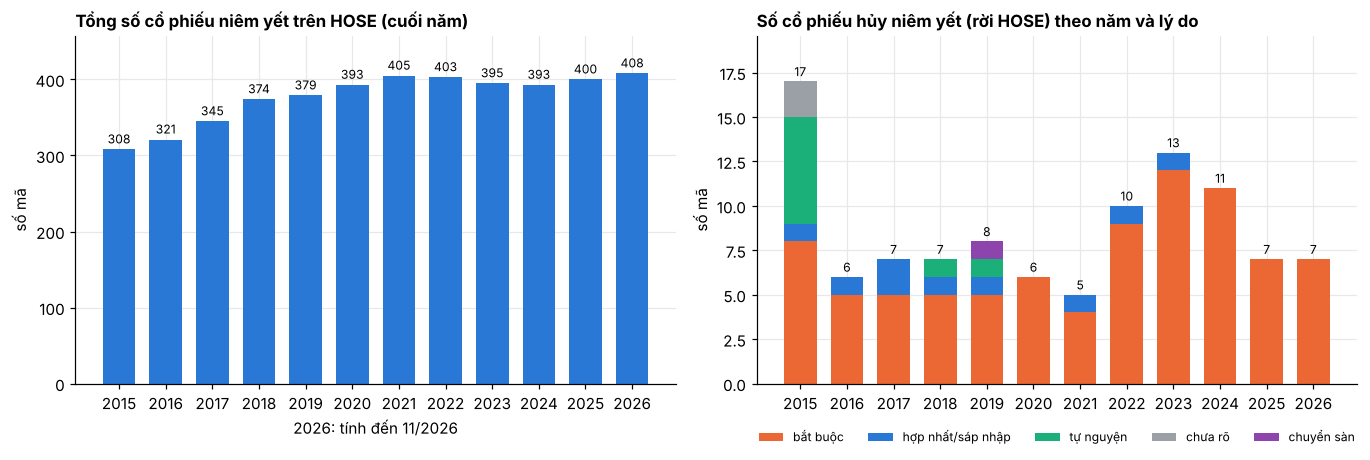

Lý do hủy: {'bắt buộc': 84, 'hợp nhất/sáp nhập': 9, 'tự nguyện': 8, 'chưa rõ': 2, 'chuyển sàn': 1}


In [15]:
# T1b. Số cổ phiếu niêm yết (cuối năm) và số cổ phiếu hủy niêm yết theo năm, tách theo lý do
REASON = {"bat_buoc": "bắt buộc", "hop_nhat": "hợp nhất/sáp nhập", "tu_nguyen": "tự nguyện", "chuyen_san": "chuyển sàn", "chua_ro": "chưa rõ"}
REASON_COL = {"bắt buộc": "#eb6834", "hợp nhất/sáp nhập": "#2a78d6", "tự nguyện": "#1baf7a", "chuyển sàn": "#8e44ad", "chưa rõ": "#9aa0a6"}
years = list(range(P.index[0].year, P.index[-1].year + 1))
year_end = {y: min(pd.Timestamp(f"{y}-12-31"), P.index[-1]) for y in years}

def n_listed(day):
    """Số mã đang niêm yết vào ngày `day` theo security_master."""
    return sum(1 for r in MASTER.itertuples() if r.listing_date <= day and (pd.isna(r.delisting_date) or r.delisting_date >= day))

listed = pd.Series({y: n_listed(year_end[y]) for y in years})
by_reason = (dl.assign(year=dl.delisting_date.dt.year, reason=dl.reason.map(REASON).fillna("chưa rõ"))
               .pivot_table(index="year", columns="reason", values="ticker", aggfunc="count", fill_value=0)
               .reindex(years, fill_value=0))
by_reason = by_reason[by_reason.sum().sort_values(ascending=False).index]          # lý do nhiều nhất ở dưới cùng

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
bars = ax[0].bar(years, listed.values, color="#2a78d6", width=.7)
ax[0].bar_label(bars, fontsize=8, padding=2)
ax[0].set(title="Tổng số cổ phiếu niêm yết trên HOSE (cuối năm)", xticks=years, ylim=(0, listed.max() * 1.12), ylabel="số mã")
ax[0].set_xlabel("2026: tính đến 11/2026")

bottom = np.zeros(len(years))
for reason in by_reason.columns:
    ax[1].bar(years, by_reason[reason], bottom=bottom, width=.7, color=REASON_COL[reason], label=reason); bottom += by_reason[reason].values
for x, v in zip(years, bottom): ax[1].text(x, v + .3, str(int(v)), ha="center", fontsize=8)
ax[1].set(title="Số cổ phiếu hủy niêm yết (rời HOSE) theo năm và lý do", xticks=years, ylim=(0, bottom.max() * 1.15), ylabel="số mã")
ax[1].legend(ncol=5, loc="upper center", bbox_to_anchor=(.5, -.1), fontsize=8)
fig.tight_layout(); plt.show()
print("Lý do hủy:", dl.reason.map(REASON).fillna("chưa rõ").value_counts().to_dict())

**Nhận xét T1b.**
- **Hình trái:** số cổ phiếu niêm yết tăng từ 308 (cuối 2015) lên đỉnh 405 (2021), rồi 393–408 đến 11/2026.
- **Hình phải:** mỗi năm có 5–17 mã rời HOSE, không năm nào bằng 0 (nhiều nhất 2015: 17; 2023: 13; 2024: 11).
- **Lý do:** bắt buộc 84 (81%), hợp nhất/sáp nhập 9, tự nguyện 8, chưa rõ 2, chuyển sàn 1.

,số mã,thiếu giá,không qua lớp 1,bị lớp 2 loại (đứng giá),"qua lớp 2, không vào top-N",được chọn vào top-N
nhóm,,,,,,
bắt buộc,84,11,22,2,20,29
hợp nhất/sáp nhập,9,4,0,2,2,1
tự nguyện,8,3,4,0,0,1
chuyển sàn / chưa rõ,3,1,1,0,0,1
còn niêm yết (so sánh),408,0,47,6,128,227
TỔNG mã hủy,104,19,27,4,22,32


Tỷ lệ mã được chọn ≥ 1 kỳ vào top-100: mã hủy 31% | mã còn niêm yết 56%  (trên 118 kỳ có vũ trụ)


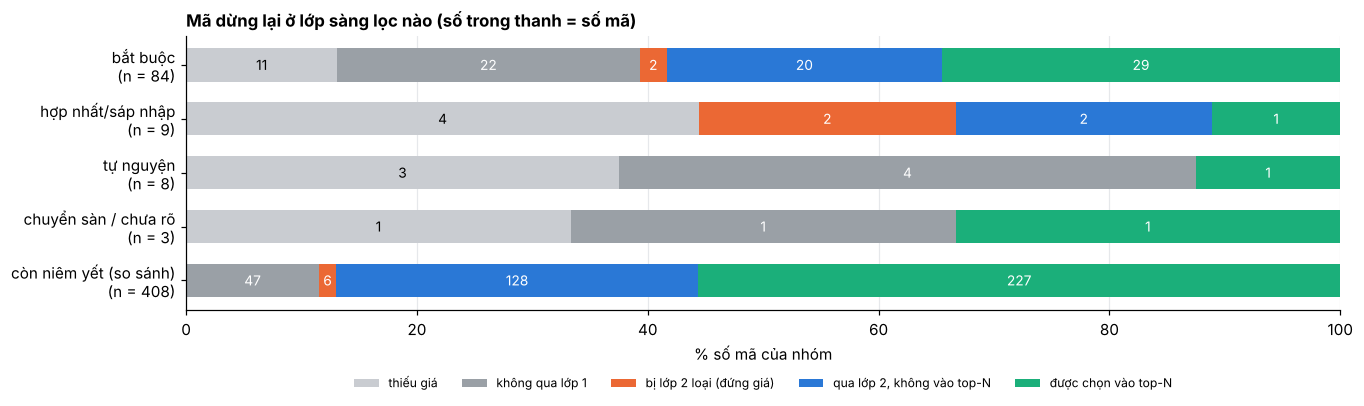

In [16]:
# T1c. "Màng sàng lọc": mã hủy niêm yết (theo lý do) đi qua từng lớp như thế nào.
# Chạy lại đúng bước chọn vũ trụ của §3 (không backtest) và ghi lại mã đi qua mỗi lớp ở mỗi kỳ tái cân bằng:
#   lớp 1: ≥ 95% phiên có giá trong cửa sổ 250 phiên và có giá ngày hôm trước
#   lớp 2: ≤ ZERO_MAX phiên đứng giá (r = 0) trong cửa sổ
#   lớp 3: N mã có giá trị GD trung vị cao nhất (kỳ không đủ N mã sau lớp 2 bị bỏ)
N_, WIN, REB = CONFIG["N"], CONFIG["WINDOW"], CONFIG["REB"]
Rm = R_q.mask(R_q.abs() > CONFIG["MAX_ABS_RET"], 0.0)                       # |r| > 15% coi là lỗi, đặt = 0 (đúng như run_backtest)
layer1, layer2, chosen, stopped, n_periods = set(), set(), set(), [], 0
for s in range(WIN + 1, len(P) - 1, REB):
    win = Rm.iloc[s - WIN:s]
    ok1 = (win.notna().mean() >= .95) & P.iloc[s - 1].notna()
    ok2 = ok1 & ((win == 0).mean() <= CONFIG["ZERO_MAX"])
    layer1 |= set(ok1[ok1].index); layer2 |= set(ok2[ok2].index)
    if ok2.sum() < N_: continue
    n_periods += 1
    top = V.iloc[s - WIN:s].loc[:, ok2].median().sort_values(ascending=False).index[:N_]
    chosen |= set(top); hold_end = P.index[min(s + REB, len(P)) - 1]
    for t in top:                                                            # mã không còn giá nào đến hết kỳ giữ ⇒ ngừng giao dịch trong kỳ
        last = P[t].last_valid_index()
        if last < hold_end: stopped.append({"kỳ tái cân bằng": P.index[s].date(), "mã": t, "ngày có giá cuối": last.date()})

GROUP = {"bắt buộc": "bắt buộc", "hợp nhất/sáp nhập": "hợp nhất/sáp nhập", "tự nguyện": "tự nguyện", "chuyển sàn": "chuyển sàn / chưa rõ", "chưa rõ": "chuyển sàn / chưa rõ"}
dl["nhóm"] = dl.reason.map(REASON).fillna("chưa rõ").map(GROUP)
alive = [c for c in P.columns if c not in set(dl.ticker)]
members = {g: set(dl.loc[dl["nhóm"] == g, "ticker"]) for g in ["bắt buộc", "hợp nhất/sáp nhập", "tự nguyện", "chuyển sàn / chưa rõ"]}
members["còn niêm yết (so sánh)"] = set(alive)
all_mem = {g: set(m) for g, m in members.items()}
rows = []
for g, m in members.items():
    n_all = len(dl[dl["nhóm"] == g]) if g in GROUP.values() else len(m)
    has = m & set(P.columns)
    rows.append({"nhóm": g, "số mã": n_all, "thiếu giá": n_all - len(has), "không qua lớp 1": len(has) - len(has & layer1),
                 "bị lớp 2 loại (đứng giá)": len(has & layer1) - len(has & layer2), "qua lớp 2, không vào top-N": len(has & layer2) - len(has & chosen),
                 "được chọn vào top-N": len(has & chosen)})
FUN = pd.DataFrame(rows).set_index("nhóm")
FUN.loc["TỔNG mã hủy"] = FUN.iloc[:4].sum()
display(FUN)
print(f"Tỷ lệ mã được chọn ≥ 1 kỳ vào top-{N_}: mã hủy {FUN.loc['TỔNG mã hủy', 'được chọn vào top-N'] / FUN.loc['TỔNG mã hủy', 'số mã']:.0%} "
      f"| mã còn niêm yết {FUN.loc['còn niêm yết (so sánh)', 'được chọn vào top-N'] / FUN.loc['còn niêm yết (so sánh)', 'số mã']:.0%}  (trên {n_periods} kỳ có vũ trụ)")

# hình: mỗi nhóm là một thanh 100%, màu = mã dừng lại ở lớp nào
stages = ["thiếu giá", "không qua lớp 1", "bị lớp 2 loại (đứng giá)", "qua lớp 2, không vào top-N", "được chọn vào top-N"]
stage_col = ["#c9ccd1", "#9aa0a6", "#eb6834", "#2a78d6", "#1baf7a"]
plot = FUN.drop(index="TỔNG mã hủy")[stages]; share = plot.div(plot.sum(1), axis=0) * 100
fig, ax = plt.subplots(figsize=(12.5, 3.9)); y = np.arange(len(plot))[::-1]; left = np.zeros(len(plot))
for st, c in zip(stages, stage_col):
    ax.barh(y, share[st], left=left, color=c, height=.62, label=st)
    for yi, (v, n, l0) in enumerate(zip(share[st], plot[st], left)):
        if n > 0: ax.text(l0 + v / 2, y[yi], str(int(n)), ha="center", va="center", fontsize=9, color="white" if c in ("#eb6834", "#2a78d6", "#1baf7a", "#9aa0a6") else "black")
    left += share[st].values
ax.set_yticks(y, [f"{g}\n(n = {int(FUN.loc[g, 'số mã'])})" for g in plot.index]); ax.set_xlim(0, 100); ax.grid(axis="y", visible=False)
ax.set_xlabel("% số mã của nhóm"); ax.set_title("Mã dừng lại ở lớp sàng lọc nào (số trong thanh = số mã)")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(.5, -.2), fontsize=8)
fig.tight_layout(); plt.show()

**Nhận xét T1c (màng sàng lọc).**
- **Mọi loại hủy đi qua cùng một bộ lọc**; lý do hủy không được dùng. Mã dừng ở đâu chỉ tùy dữ liệu của mã đó.
- **Hủy bắt buộc (84 mã):** 11 thiếu giá, 22 không đủ dữ liệu (lớp 1), 2 bị loại vì đứng giá, 20 qua lọc nhưng không vào top-100, **29 từng được chọn vào top-100** (như FLC, HNG, HBC, HAI, DAG, ITA). Hợp nhất (9) và tự nguyện (8): phần lớn thiếu giá hoặc không đủ dữ liệu, mỗi nhóm có 1 mã từng được chọn.
- **So sánh:** 31% mã hủy (32/104) từng vào top-100, so với 56% mã còn niêm yết (227/408). Mã hủy **không hiếm** trong danh mục ⇒ bỏ chúng đi sẽ gây survivorship bias.
- Lọc đứng giá chỉ loại 4/104 mã hủy (2 bắt buộc, 2 hợp nhất).

In [17]:
# T1d. Mã đang được giữ thì ngừng giao dịch trong kỳ giữ: bộ lọc xử lý thế nào?
# Quy ước của thầy (§3): ngày không có giá ⇒ lợi suất 0, tức giữ nguyên giá cuối đến kỳ tái cân bằng kế tiếp, sau đó mã tự rơi khỏi vũ trụ (không còn giá hôm trước).
STOP = pd.DataFrame(stopped)
events = dl.sort_values("delisting_date").drop_duplicates("ticker", keep="last").set_index("ticker")
STOP["ngày hủy chính thức"] = STOP["mã"].map(events["delisting_date"]).dt.date
STOP["lý do"] = STOP["mã"].map(events["reason"].map(REASON).fillna("chưa rõ"))
STOP["ngừng GD trước hủy (ngày)"] = [(pd.Timestamp(d) - pd.Timestamp(l)).days if pd.notna(d) else np.nan for d, l in zip(STOP["ngày hủy chính thức"], STOP["ngày có giá cuối"])]
display(STOP.set_index("kỳ tái cân bằng"))
print(f"{len(STOP)} vị thế (trên {n_periods} kỳ × {N_} mã = {n_periods * N_}) ngừng giao dịch ngay trong kỳ giữ; {STOP['mã'].nunique()} mã khác nhau.")

,mã,ngày có giá cuối,ngày hủy chính thức,lý do,ngừng GD trước hủy (ngày)
kỳ tái cân bằng,,,,,
2017-01-09,ATA,2017-02-03,2017-02-06,bắt buộc,3
2020-05-27,LMH,2020-06-18,2020-06-19,bắt buộc,1
2022-07-29,ROS,2022-08-11,2022-09-05,bắt buộc,25
2022-08-29,FLC,2022-09-08,2023-02-20,bắt buộc,165
2024-09-06,ITA,2024-09-25,2025-02-04,bắt buộc,132
2025-09-11,BCG,2025-10-08,2026-07-15,bắt buộc,280


6 vị thế (trên 118 kỳ × 100 mã = 11800) ngừng giao dịch ngay trong kỳ giữ; 6 mã khác nhau.


**Nhận xét T1d (mã ngừng giao dịch giữa kỳ giữ).**
- Có **6 vị thế** trên 11.800 (118 kỳ × 100 mã) ngừng giao dịch ngay trong kỳ giữ: ATA (2017), LMH (2020), ROS và FLC (2022), ITA (2024), BCG (2025); cả 6 đều là hủy bắt buộc.
- Sàn đình chỉ giao dịch **trước** ngày hủy chính thức: từ 1 ngày (LMH) đến 280 ngày (BCG); FLC 165 ngày, ITA 132 ngày.
- Quy ước của thầy: ngày không có giá nhận lợi suất 0, tức coi như bán ở giá cuối và giữ tiền mặt. Thực tế nhà đầu tư không bán được, và các mã này thường giảm mạnh sau đó ⇒ quy ước hơi lạc quan (6 vị thế = 0,05%, ảnh hưởng nhỏ). Có thể hỏi thầy có cần mức phạt không.

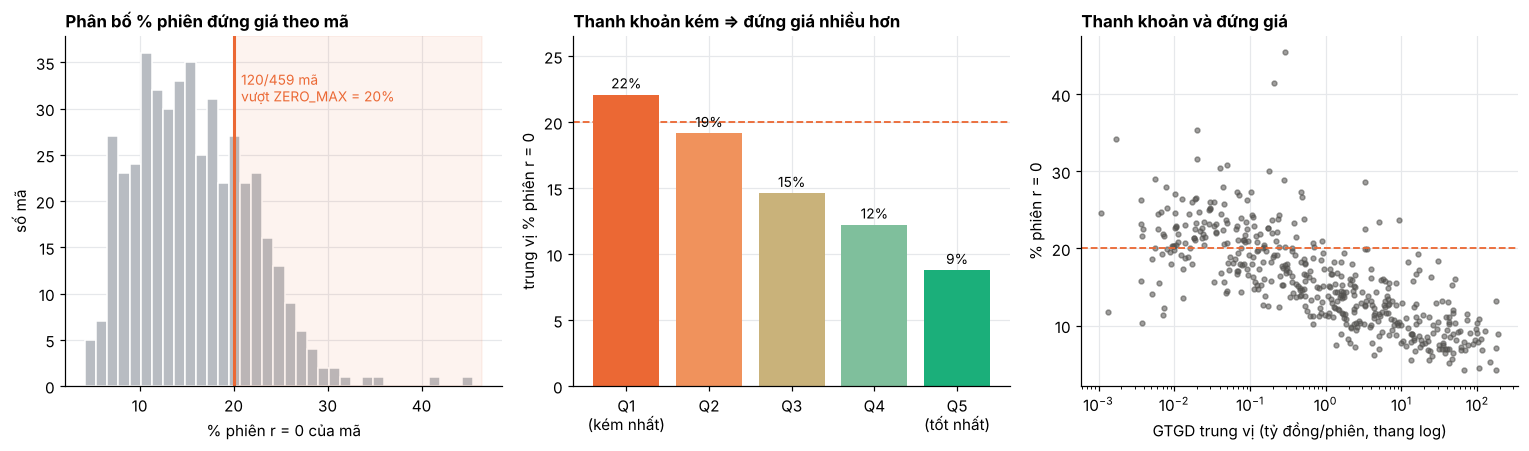

,số kỳ đủ N = 100 mã (/129),số mã đủ điều kiện: trung vị,nhỏ nhất
ZERO_MAX,,,
không lọc,129,278,166
20% (chuẩn),118,249,61
10%,69,114,3


Tương quan hạng (GTGD, % r = 0) = -0.78


In [18]:
# T1e. Mã đứng giá (lớp 2): tỷ lệ phiên r = 0 của từng mã, liên hệ với thanh khoản, và hệ quả lên số kỳ đủ N mã
n_obs = R_q.notna().sum()
zero_share = ((R_q == 0).sum() / n_obs)[n_obs >= 250] * 100                         # % phiên r = 0 của mỗi mã (mã có ≥ 250 phiên)
liq = V.median()[zero_share.index] / 1e9                                           # GTGD trung vị (tỷ đồng/phiên)
quint = pd.qcut(liq.rank(method="first"), 5, labels=["Q1\n(kém nhất)", "Q2", "Q3", "Q4", "Q5\n(tốt nhất)"])
zmax = 100 * CONFIG["ZERO_MAX"]

fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
ax[0].hist(zero_share, bins=35, color=GREY, edgecolor="white")
ax[0].axvline(zmax, color="#eb6834", lw=2); ax[0].axvspan(zmax, zero_share.max() + 1, color="#eb6834", alpha=.08)
ax[0].text(zmax + .8, ax[0].get_ylim()[1] * .9, f"{int((zero_share > zmax).sum())}/{len(zero_share)} mã\nvượt ZERO_MAX = {zmax:.0f}%", color="#eb6834", fontsize=9, va="top")
ax[0].set(title="Phân bố % phiên đứng giá theo mã", xlabel="% phiên r = 0 của mã", ylabel="số mã")
med = zero_share.groupby(quint, observed=True).median()
bars = ax[1].bar(range(5), med.values, color=["#eb6834", "#f0925c", "#c9b27a", "#7fbf9c", "#1baf7a"])
ax[1].bar_label(bars, fmt="%.0f%%", fontsize=9, padding=2); ax[1].axhline(zmax, color="#eb6834", lw=1.2, ls="--")
ax[1].set(title="Thanh khoản kém ⇒ đứng giá nhiều hơn", xticks=range(5), xticklabels=med.index, ylabel="trung vị % phiên r = 0", ylim=(0, med.max() * 1.2))
ax[2].scatter(liq, zero_share, s=10, alpha=.55, color="#52514e"); ax[2].axhline(zmax, color="#eb6834", lw=1.2, ls="--"); ax[2].set_xscale("log")
ax[2].set(title="Thanh khoản và đứng giá", xlabel="GTGD trung vị (tỷ đồng/phiên, thang log)", ylabel="% phiên r = 0")
fig.tight_layout(); plt.show()

# số kỳ đủ N mã theo ngưỡng lọc (cơ sở chọn ZERO_MAX)
rows = []
for s in range(WIN + 1, len(P) - 1, REB):
    win = Rm.iloc[s - WIN:s]; ok = (win.notna().mean() >= .95) & P.iloc[s - 1].notna(); zs = (win == 0).mean()
    rows.append({z: int((ok & (zs <= z)).sum()) for z in (1.0, 0.2, 0.1)})
EL = pd.DataFrame(rows)
display(pd.DataFrame({"ZERO_MAX": ["không lọc", "20% (chuẩn)", "10%"], f"số kỳ đủ N = {N_} mã (/{len(EL)})": [(EL[z] >= N_).sum() for z in EL],
                      "số mã đủ điều kiện: trung vị": [int(EL[z].median()) for z in EL], "nhỏ nhất": [int(EL[z].min()) for z in EL]}).set_index("ZERO_MAX"))
print(f"Tương quan hạng (GTGD, % r = 0) = {liq.rank().corr(zero_share.rank()):.2f}")

**Nhận xét T1e (mã đứng giá).**
- 120/459 mã (mã có ≥ 250 phiên) có hơn 20% phiên đứng giá. Thanh khoản càng kém càng đứng giá nhiều: trung vị 22% ở nhóm kém nhất, 9% ở nhóm tốt nhất; tương quan hạng −0,78.
- Lọc `ZERO_MAX = 20%` giữ 118/129 kỳ đủ 100 mã (trung vị 249 mã); lọc 10% chỉ còn 69/129 kỳ; không lọc đủ 129/129.
- Đứng giá là đặc điểm của mã kém thanh khoản, không phải lỗi dữ liệu; lọc để danh mục không bị dồn vào mã "trông ít biến động".

## Ghi chú T1
- **Dữ liệu:** `data_hose/` phủ 2015-01 → 2026-11 (gồm 2020–2025). Mã hủy niêm yết lấy từ HSX + Vietstock + VCI; 19 mã VCI không còn giá.
- **Mã hủy giữa kỳ giữ:** lợi suất 0 sau ngày có giá cuối (đúng quy ước của thầy), không có mức phạt mất giá.
- **Chưa làm (để sau T1):** sửa EW-NL-LW khi N > T_eff, đối chứng WeSpeR, chạy lại §3–§4 và T2–T6 với lọc đứng giá.